# Домашнее задание 4. Деревья и ансамбли
## Математические методы анализа данных

В этом ДЗ вы участвуете в соревновании **«Лес учится видеть»**: строите модель на основе деревьев решений и предсказываете класс каждого пикселя изображения.

**Дата публикации:** 9 ноября 2026.  
**Дедлайн:** 21 ноября 2026, 23:00 (МСК).  
**Максимальный балл:** 10.

Для сдачи в LMS заполните **карточку участника** в конце этого ноутбука и коротко поясните, за счёт чего ваш скор выше, чем у базового решения. Исполняемое решение загружается на платформу соревнования. Проверяющий находит вас по имени в лидерборде и рассчитывает оценку по результату на **private**.

# Лес учится видеть · решение

Тетрадь лежит рядом с распакованной папкой `data/`; все ячейки запускаются по порядку, последняя создаёт `submission.csv`.

Что изменено относительно базового решения:

1. **Признаки.** К трём базовым добавлено около 150 признаков текстуры: вариограммы (разности с соседом на лагах 1–7 px в 4 направлениях, нормированные на локальную дисперсию) на трёх масштабах, те же вариограммы в окнах, сдвинутых от пикселя, структурный тензор, энергия лапласиана гауссиана.
2. **Двухэтапная модель (auto-context).** Этап 1: два леса по 25 деревьев, каждый учится на одной обучающей картинке и даёт out-of-fold вероятности для другой. Этап 2: лес из 50 деревьев получает исходные признаки плюс сглаженные и сдвинутые карты вероятностей этапа 1. Всего ровно 100 деревьев и 20 000 обучающих пикселей.
3. **Постобработка.** Карты вероятностей сглаживаются гауссианом, затем берётся argmax. Ширина сглаживания подбирается по открытой валидации.

In [ ]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import uniform_filter, maximum_filter, minimum_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from matplotlib.patches import Patch

DATA = Path('data')
WINDOW = 9
TREES = 10
PALETTE = np.array([[49, 104, 174], [221, 151, 39], [52, 144, 104], [157, 91, 164]], dtype=np.uint8)
NAMES = ['Горизонтальные штрихи', 'Вертикальные штрихи', 'Пятна', 'Диагональные полосы']

def read_public(name):
    path = DATA / name
    if not path.is_file():
        raise FileNotFoundError(f'Не найден {path}. Положите тетрадь рядом с распакованной папкой data/.')
    with Image.open(path) as image:
        return np.asarray(image).copy()

def features(gray, window, extra):
    # На исходной картинке в пикселе одно число — яркость.
    # Каждый признак добавляет этому же пикселю ещё одно число.
    # Лес получает их вместе: яркость, контраст, разность с соседом справа и то, что добавлено в my_features.
    custom = extra(gray.astype(np.float32) / 255, window)
    fields = base_features(gray, window) + list(custom)
    for field in fields:
        if np.shape(field) != gray.shape or not np.isfinite(field).all():
            raise ValueError('Каждый признак должен быть конечным массивом формы gray.shape')
    return np.stack(fields, axis=-1).astype(np.float32)

def error_panel(image, truth, pred):
    # Красным отмечен пиксель, у которого ответ леса отличается от класса в маске.
    panel = np.repeat((image * 0.4 + 30).astype(np.uint8)[:, :, None], 3, axis=2)
    panel[truth != pred] = [218, 50, 55]
    return panel

def boundary_mask(mask, k=7):
    # Пиксель на стыке: в квадрате 7×7 вокруг него лежат разные классы из маски.
    # Окно вокруг такого пикселя захватывает две текстуры сразу.
    return maximum_filter(mask, size=k, mode='nearest') != minimum_filter(mask, size=k, mode='nearest')

def error_rates(truth, pred):
    err = pred != truth
    border = boundary_mask(truth)
    return float(err[border].mean()), float(err[~border].mean())

def recall_per_class(truth, pred):
    recalls = []
    flat_t, flat_p = truth.ravel(), pred.ravel()
    for label in range(4):
        chosen = flat_t == label
        recalls.append(float((flat_p[chosen] == label).mean()) if chosen.any() else 0.0)
    return recalls

cache = {}

def get_model():
    # Модель обучается один раз и дальше берётся из кэша.
    if 'model' not in cache:
        cache['model'] = fit_model()
    return cache['model']

def show(ax, image, title):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')

## 1. Задание и ограничения

- [Условие и данные соревнования](https://vsos.colloq.ru/k/trees-textures)
- [Лидерборд соревнования](https://vsos.colloq.ru/k/trees-textures/leaderboard)

Нужно отнести каждый пиксель к одному из четырёх классов: **0, 1, 2 или 3**. Метрика — **Balanced Accuracy**, средняя полнота по четырём классам. Чем больше значение, тем лучше.

В данных есть два обучающих изображения и их маски: `train_0.png`, `train_1.png`, `mask_0.png`, `mask_1.png`. Для собственной проверки используйте `val.png` и `val_mask.png`. При проверке на платформе `data/test.png` заменяется скрытым изображением, размеры которого могут отличаться от открытого примера.

**Основные ограничения соревнования:**

- Разрешены деревья решений, случайный лес и бустинг на деревьях.
- В итоговой модели — **суммарно не более 100 деревьев**; для обучения — **не более 20 000 уникальных пикселей**. Считайте фактические деревья: у многоклассового бустинга одна итерация может создавать несколько деревьев.
- Нейросети и готовые сегментаторы запрещены.
- Ноутбук запускается с нуля, сверху вниз, **без интернета**: до **10 минут**, **4 ГБ памяти**, **2 ядра**. На платформе доступно до **5 посылок в день**.
- Результат работы — `submission.csv` с колонками `id,label`. Индексы начинаются с 0; пиксели идут слева направо, сверху вниз. Число строк определяйте по текущему `data/test.png`.

Можно экспериментировать с признаками, обработкой изображений и настройками разрешённых моделей. Полное условие и окружение проверки приведены на странице соревнования.

## 2. Признаки пикселя

Базовые признаки: яркость, стандартное отклонение в окне и средняя абсолютная разность соседей по горизонтали. В `my_features` поступает изображение с яркостями от 0 до 1; функция возвращает список двумерных массивов той же формы.

Идеи признаков:

- **Вариограмма** $\gamma_{d,k} = \overline{(I(p) - I(p + k d))^2} \,/\, 2\sigma^2$. Для горизонтальных штрихов она мала вдоль $x$ и велика вдоль $y$, у вертикальных наоборот, у диагональных полос почти нулевая вдоль полосы на всех лагах, у пятен примерно одинакова во всех направлениях и быстро растёт с лагом.
- **Сдвинутые окна.** Окно с центром в пикселе на стыке захватывает две текстуры. Окно, сдвинутое на 3 или 6 px, чаще лежит в одной текстуре, и лес может выбрать «чистое» окно.
- **Структурный тензор** даёт преобладающее направление градиента и его выраженность (когерентность).
- **Лапласиан гауссиана** выделяет изотропные пятна.

Все признаки нормированы на локальный контраст, поэтому не зависят от общей яркости картинки.

In [ ]:
def mean_window(a, window):
    # Для каждого пикселя считаем среднее по квадрату вокруг него.
    # У края картинки квадрат вылезает наружу. Недостающие пиксели берём зеркальным отражением.
    return uniform_filter(a.astype(np.float32), size=window, mode='reflect')

def base_features(gray, window):
    # В файле яркость — целое от 0 до 255. Нормализуем к диапазону 0 - 1
    image = gray.astype(np.float32) / 255
    # Насколько сильно яркость скачет внутри окна - это контраст
    # Горизонтальный и вертикальный штрих одинаковой резкости дают похожее число
    local_mean = mean_window(image, window)
    local_sd = np.sqrt(np.maximum(mean_window(image * image, window) - local_mean**2, 0))
    # Насколько этот пиксель отличается от соседа справа.
    # Вычитание даёт минус, если сосед темнее. Модуль убирает знак, остаётся величина от 0 до 1.
    # Вертикальный штрих дает большое отличие слева направо
    # Горизонтальный штрих идёт вдоль строки, сосед справа похож, отличие маленькое.
    dx = np.abs(np.diff(image, axis=1, append=image[:, -1:]))
    return [image, local_sd, mean_window(dx, window)]


In [ ]:
from scipy.ndimage import gaussian_filter, gaussian_laplace

EPS = 1e-6
DIRS = [(0, 1), (1, 0), (1, 1), (1, -1)]   # вправо, вниз, две диагонали
LAGS = [1, 2, 3, 5, 7]                     # на сколько пикселей сравниваем
SCALES = [1.5, 3.0, 6.0]                   # радиусы гауссова окна
SHIFT_R = [3, 6]                           # сдвиг окна от пикселя


def gblur(a, s):
    return gaussian_filter(a, s, mode='reflect')


def shift(a, dy, dx):
    # Значение a[y + dy, x + dx], у края зеркальное отражение.
    h, w = a.shape
    p = max(abs(dy), abs(dx))
    b = np.pad(a, p, mode='reflect')
    return b[p + dy:p + dy + h, p + dx:p + dx + w]


def my_features(gray, window):
    # Нормируем яркость картинки целиком: признаки не зависят от общей яркости и контраста.
    img = gray.astype(np.float32)
    img = (img - img.mean()) / (img.std() + EPS)
    out = []

    # 1. Локальная дисперсия на нескольких масштабах.
    var = {}
    for s in [1.5, 3.0, 6.0, 10.0]:
        m = gblur(img, s)
        var[s] = np.maximum(gblur(img * img, s) - m * m, 0) + 1e-3
        out.append(np.log(var[s]))

    # 2. Вариограмма: средний квадрат разности с соседом на расстоянии k
    #    в 4 направлениях, делённый на дисперсию. Вдоль штриха разность мала, поперёк велика.
    #    Для диагональных полос разность вдоль полосы почти 0 на всех лагах.
    sq = {}
    for dy, dx in DIRS:
        for k in LAGS:
            d = img - shift(img, dy * k, dx * k)
            sq[(dy, dx, k)] = d * d
    for s in SCALES:
        for d2 in sq.values():
            out.append(gblur(d2, s) / (2 * var[s]))

    # 3. Те же вариограммы в окне, сдвинутом от пикселя на 3 и 6 px влево/вправо/вверх/вниз.
    #    У границы двух текстур хотя бы одно из сдвинутых окон целиком лежит в «своей» текстуре.
    base = {key: gblur(d2, 3.0) for key, d2 in sq.items() if key[2] in (1, 3)}
    for r in SHIFT_R:
        for uy, ux in [(0, 1), (0, -1), (1, 0), (-1, 0)]:
            v = shift(var[3.0], uy * r, ux * r)
            for b in base.values():
                out.append(shift(b, uy * r, ux * r) / (2 * v))

    # 4. Структурный тензор: доминирующее направление градиента и его выраженность.
    for pre in [0.7, 1.5]:
        gy, gx = np.gradient(gblur(img, pre))
        for s in [1.5, 3.0, 6.0]:
            jxx, jyy, jxy = gblur(gx * gx, s), gblur(gy * gy, s), gblur(gx * gy, s)
            tr = jxx + jyy + EPS
            out += [(jxx - jyy) / tr,                                   # горизонталь против вертикали
                    2 * jxy / tr,                                       # диагональ / против \
                    np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / tr,      # когерентность
                    np.log(tr)]                                         # сила градиента

    # 5. Энергия лапласиана гауссиана: пятна дают сильный изотропный отклик.
    for s in [1.0, 2.0]:
        lap = gaussian_laplace(img, s) * s * s
        for t in [3.0, 6.0]:
            out.append(gblur(lap * lap, t) / var[t])
    return out

## 3. Открытая валидация и её разметка

На входе — чёрно-белое изображение. Для каждого пикселя нужно предсказать один из четырёх классов текстуры. Ниже — открытая валидация и её разметка.


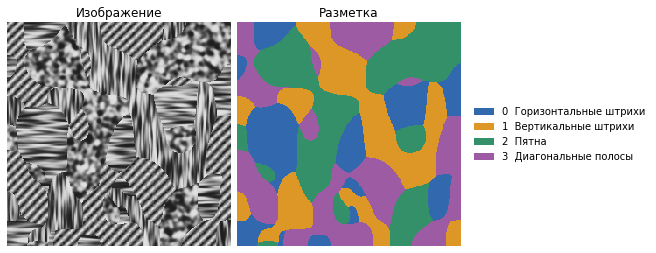

In [3]:
train = read_public('val.png')
mask = read_public('val_mask.png')

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
show(axes[0], train, 'Изображение')
axes[1].imshow(PALETTE[mask], interpolation='nearest')
axes[1].set_title('Разметка')
axes[1].axis('off')
axes[1].legend(
    handles=[Patch(facecolor=PALETTE[i] / 255, label=f'{i}  {NAMES[i]}') for i in range(4)],
    loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False,
)
plt.show()


## 4. Два пикселя одной яркости

Красная рамка отмечает центр каждого фрагмента. В обоих случаях яркость равна 128. Какой признак позволит дереву различить направления штрихов?


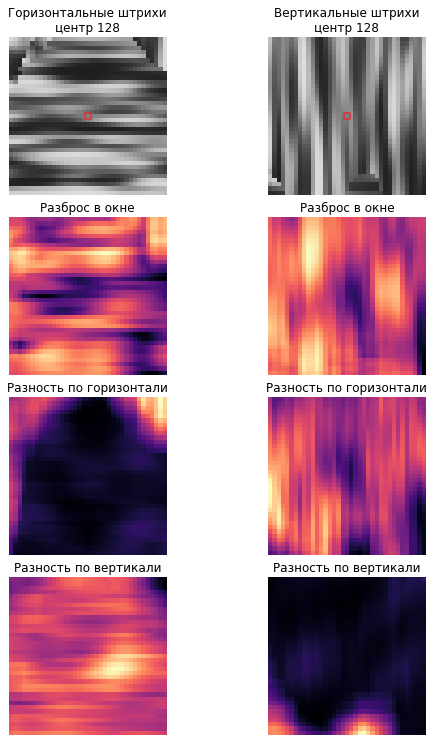

In [4]:
def pick_patch(label, radius=18):
    best = None
    best_score = -1e9
    for name_i in range(2):
        image = read_public(f'train_{name_i}.png')
        mask = read_public(f'mask_{name_i}.png')
        height, width = image.shape
        ys, xs = np.where((image == 128) & (mask == label))
        for y, x in zip(ys.tolist(), xs.tolist()):
            if not (radius <= y < height - radius and radius <= x < width - radius):
                continue
            view = (slice(y - radius, y + radius + 1), slice(x - radius, x + radius + 1))
            if (mask[view] == label).mean() < 0.7:
                continue
            crop = image[view].astype(np.float32)
            dx = np.abs(np.diff(crop, axis=1)).mean()
            dy = np.abs(np.diff(crop, axis=0)).mean()
            score = (dy - dx) if label == 0 else (dx - dy)
            if score > best_score:
                best_score = float(score)
                best = (name_i, int(y), int(x))
    if best is None:
        raise RuntimeError(f'Не нашёлся фрагмент класса {label} с яркостью 128 в центре')
    return best

def crop_at(array, y, x, radius):
    return array[y - radius:y + radius + 1, x - radius:x + radius + 1]

radius = 18
choice = [pick_patch(0, radius), pick_patch(1, radius)]
fig, axes = plt.subplots(4, 2, figsize=(7.2, 10.2), constrained_layout=True)
row_names = ['Фрагмент', 'Разброс в окне', 'Разность по горизонтали', 'Разность по вертикали']
for column, (name_i, y, x) in enumerate(choice):
    image = read_public(f'train_{name_i}.png')
    maps = features(image, WINDOW, lambda gray, window: [])
    # То же сравнение, но с соседом снизу. Эта картинка только на рисунке, лес её не получает.
    vertical = mean_window(
        np.abs(np.diff(image.astype(np.float32) / 255, axis=0, append=image[-1:, :])),
        WINDOW,
    )
    panels = [image, maps[:, :, 1], maps[:, :, 2], vertical]
    for row, panel in enumerate(panels):
        ax = axes[row, column]
        view = crop_at(panel, y, x, radius)
        if row == 0:
            show(ax, view, f'{NAMES[column]}\nцентр {int(image[y, x])}')
            ax.plot(radius, radius, 's', ms=6, mfc='none', mec='#da3237', mew=1.5)
        else:
            ax.imshow(view, cmap='magma', interpolation='nearest')
            ax.set_title(row_names[row])
            ax.axis('off')
plt.show()


## 5. Как выглядят новые признаки

Ниже несколько признаков на открытой валидации: базовые и по одному из каждой группы новых.

In [ ]:
view = read_public('val.png')
maps = features(view, WINDOW, my_features)
print(f'Признаков на пиксель: {maps.shape[-1]}')
# индексы: 3 + 4 дисперсии; вариограммы σ=3: лаг 3 вдоль x, вдоль y, вдоль диагонали \, вдоль /; когерентность тензора
off = 3 + 4 + 20  # начало вариограмм на масштабе 3.0
picks = [(0, 'Яркость'), (1, 'Разброс'), (2, 'Разность по горизонтали'),
         (off + 2, 'Вариограмма →, лаг 3'), (off + 7, 'Вариограмма ↓, лаг 3'),
         (off + 12, 'Вариограмма ↘, лаг 3'), (off + 17, 'Вариограмма ↙, лаг 3')]
fig, axes = plt.subplots(1, len(picks), figsize=(2.6 * len(picks), 3.0), constrained_layout=True)
for ax, (channel, title) in zip(axes, picks):
    ax.imshow(maps[:, :, channel], cmap='magma', interpolation='nearest')
    ax.set_title(title, fontsize=9)
    ax.axis('off')
plt.show()

## 6. Обучение

Из каждой обучающей маски выбираем 10 000 пикселей без повторов (всего 20 000). Этап 1: лес $j$ учится на картинке $j$ и предсказывает вероятности для всех пикселей другой картинки, так что признаки контекста для обучения второго этапа получены out-of-fold. При предсказании вероятности этапа 1 усредняются по обоим лесам.

In [ ]:
PIXELS_PER_IMAGE = 10000     # 2 × 10 000 = 20 000 уникальных пикселей
TREES_STAGE1 = 25            # по 25 деревьев в каждом из двух лесов первого этапа
TREES_STAGE2 = 50            # 50 деревьев во втором этапе; итого 100
CTX_SIGMAS = [1.5, 3.0, 6.0, 12.0]


def sample_ids(images):
    rng = np.random.default_rng(41)
    return [rng.choice(im.size, min(PIXELS_PER_IMAGE, im.size), replace=False) for im in images]


def smooth_proba(P, s):
    if s <= 0:
        return P
    return np.stack([gblur(P[..., c], s) for c in range(P.shape[-1])], axis=-1)


def context(P):
    # Признаки второго этапа: вероятности первого этапа, сглаженные на разных масштабах,
    # и сглаженные вероятности в точках, сдвинутых на 4 и 8 px в 8 направлениях.
    out = [P] + [smooth_proba(P, s) for s in CTX_SIGMAS]
    Ps = smooth_proba(P, 2.0)
    for r in [4, 8]:
        for dy, dx in [(0, 1), (0, -1), (1, 0), (-1, 0), (1, 1), (-1, -1), (1, -1), (-1, 1)]:
            out.append(np.stack([shift(Ps[..., c], dy * r, dx * r) for c in range(4)], axis=-1))
    return np.concatenate(out, axis=-1).astype(np.float32)


def forest(n, seed):
    return RandomForestClassifier(n_estimators=n, min_samples_leaf=1, max_features='sqrt',
                                  random_state=seed, n_jobs=2)


def fit_model():
    images = [read_public(f'train_{i}.png') for i in range(2)]
    masks = [read_public(f'mask_{i}.png') for i in range(2)]
    ids = sample_ids(images)
    feats = [features(im, WINDOW, my_features) for im in images]
    flat = [f.reshape(f.shape[0] * f.shape[1], -1) for f in feats]
    ys = [m.ravel()[i] for m, i in zip(masks, ids)]

    # Этап 1: лес j учится на своей картинке и предсказывает другую (out-of-fold).
    stage1 = [forest(TREES_STAGE1, 41 + j).fit(flat[j][ids[j]], ys[j]) for j in range(2)]
    rows = []
    for j in range(2):
        P = stage1[1 - j].predict_proba(flat[j]).reshape(*images[j].shape, 4)
        f2 = np.concatenate([feats[j], context(P)], axis=-1)
        rows.append(f2.reshape(images[j].size, -1)[ids[j]])

    # Этап 2: те же пиксели, к признакам добавлен пространственный контекст из этапа 1.
    stage2 = forest(TREES_STAGE2, 43).fit(np.concatenate(rows), np.concatenate(ys))
    return stage1, stage2


def count_trees(model):
    stage1, stage2 = model
    return sum(len(m.estimators_) for m in stage1) + len(stage2.estimators_)


def predict_proba_image(model, image):
    stage1, stage2 = model
    f = features(image, WINDOW, my_features)
    X = f.reshape(image.size, -1)
    P = np.mean([m.predict_proba(X) for m in stage1], axis=0).reshape(*image.shape, 4)
    f2 = np.concatenate([f, context(P)], axis=-1)
    return stage2.predict_proba(f2.reshape(image.size, -1)).reshape(*image.shape, 4)


def predict_image(model, image, sigma):
    # Финальная постобработка: сглаживаем карты вероятностей и берём argmax.
    return smooth_proba(predict_proba_image(model, image), sigma).argmax(-1).astype(np.uint8)

## 7. Обучение и подбор сглаживания на открытой валидации

Обучаем модель один раз. Затем на `val.png` перебираем ширину гауссова сглаживания карт вероятностей и берём лучшую. Валидация в обучении не участвует.

In [ ]:
import time
t0 = time.time()
model = get_model()
print(f'Обучение: {time.time() - t0:.1f} с, деревьев: {count_trees(model)}')

SIGMA = 1.5  # значение по умолчанию, если валидации нет
try:
    val = read_public('val.png')
    truth = read_public('val_mask.png')
    val_proba = predict_proba_image(model, val)
    sigma_scores = {}
    for s in [0, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]:
        p = smooth_proba(val_proba, s).argmax(-1)
        sigma_scores[s] = balanced_accuracy_score(truth.ravel(), p.ravel())
        print(f'sigma = {s:<4}  BA = {sigma_scores[s]:.4f}')
    SIGMA = max(sigma_scores, key=sigma_scores.get)
except FileNotFoundError:
    val = None
print(f'Выбрано sigma = {SIGMA}')

## 8. Проверка на открытой валидации

Balanced Accuracy считается по всему `val.png`. На карте ошибок красным отмечены пиксели, у которых предсказание отличается от истинного класса.

In [ ]:
if val is not None:
    pred = smooth_proba(val_proba, SIGMA).argmax(-1).astype(np.uint8)
    score = balanced_accuracy_score(truth.ravel(), pred.ravel())
    recalls = recall_per_class(truth, pred)
    on_border, inside = error_rates(truth, pred)
    print(f'Balanced Accuracy на val: {score:.4f}')
    print(f'Ошибки: на границе {on_border:.1%}, внутри {inside:.1%}')
    print('Полнота: ' + ', '.join(f'{name} {value:.3f}' for name, value in zip(NAMES, recalls)))

    fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), constrained_layout=True)
    for ax, title, panel in zip(
        axes,
        ['Изображение', 'Разметка', 'Прогноз', 'Ошибки'],
        [val, PALETTE[truth], PALETTE[pred], error_panel(val, truth, pred)],
    ):
        show(ax, panel, title)
    plt.show()

## 9. Посылка

Сервер заменяет `data/test.png` скрытым изображением. Размер берём из файла, пиксели обходим построчно.

In [ ]:
test = read_public('test.png')
result = predict_image(model, test, SIGMA)
assert result.shape == test.shape and np.isin(result, [0, 1, 2, 3]).all()
with open('submission.csv', 'w', encoding='utf-8', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['id', 'label'])
    # Пиксели по строкам: слева направо, потом следующая строка.
    writer.writerows(enumerate(result.ravel(order='C').tolist()))
n_trees = count_trees(model)
assert n_trees <= 100
print(f'Итоговая модель: {n_trees} деревьев из 100, {2 * PIXELS_PER_IMAGE} пикселей из 20000')
print(f'submission.csv: {result.size} строк с прогнозами')

## 10. Как сдать ДЗ

1. Прочитайте условие и скачайте данные со страницы соревнования.
2. Подготовьте решение и загрузите **исполняемый `.ipynb` на платформу соревнования**. Убедитесь, что посылка успешно проверена и у вас появился результат.
3. Заполните карточку в конце этого ноутбука: ФИО, группу и **точное имя участника, как в лидерборде**. Если отображается ник с `@`, укажите его целиком. Не меняйте имя до завершения проверки ДЗ.
4. Под карточкой, в ячейке «Пояснение к решению», коротко опишите, за счёт чего ваш скор выше, чем у базового решения.
5. Переименуйте этот файл в `HW4_Фамилия_Имя.ipynb` и сдайте его **через LMS до дедлайна**.

**В LMS достаточно ноутбука с заполненной карточкой и коротким пояснением к решению.** Дублировать в нём код решения, писать отдельный отчёт или прикладывать скриншот лидерборда не требуется. PDF — версия условия для чтения; сдавать нужно `.ipynb`.

Оценка целиком определяется качеством на **приватной части теста**. За оформление, число экспериментов и текстовые ответы отдельных баллов нет.


## 12. Оценивание

Обозначим через **s** ваш итоговый **Balanced Accuracy на private**. Проверяющий берёт этот результат из приватного лидерборда после его открытия.

Границы шкалы зафиксированы по публичному лидерборду **4 ноября 2026 года**:

| Порог | Значение | Откуда взят |
|---|---:|---|
| Нижний: 0 баллов | **0,9395** | Второе место на public |
| Верхний: 10 баллов | **0,9757** | Первое место на public |

Эти числа **не меняются** при появлении новых участников или результатов. Пороги взяты с public, но в формулу подставляется именно ваш результат на private, а не место в таблице.


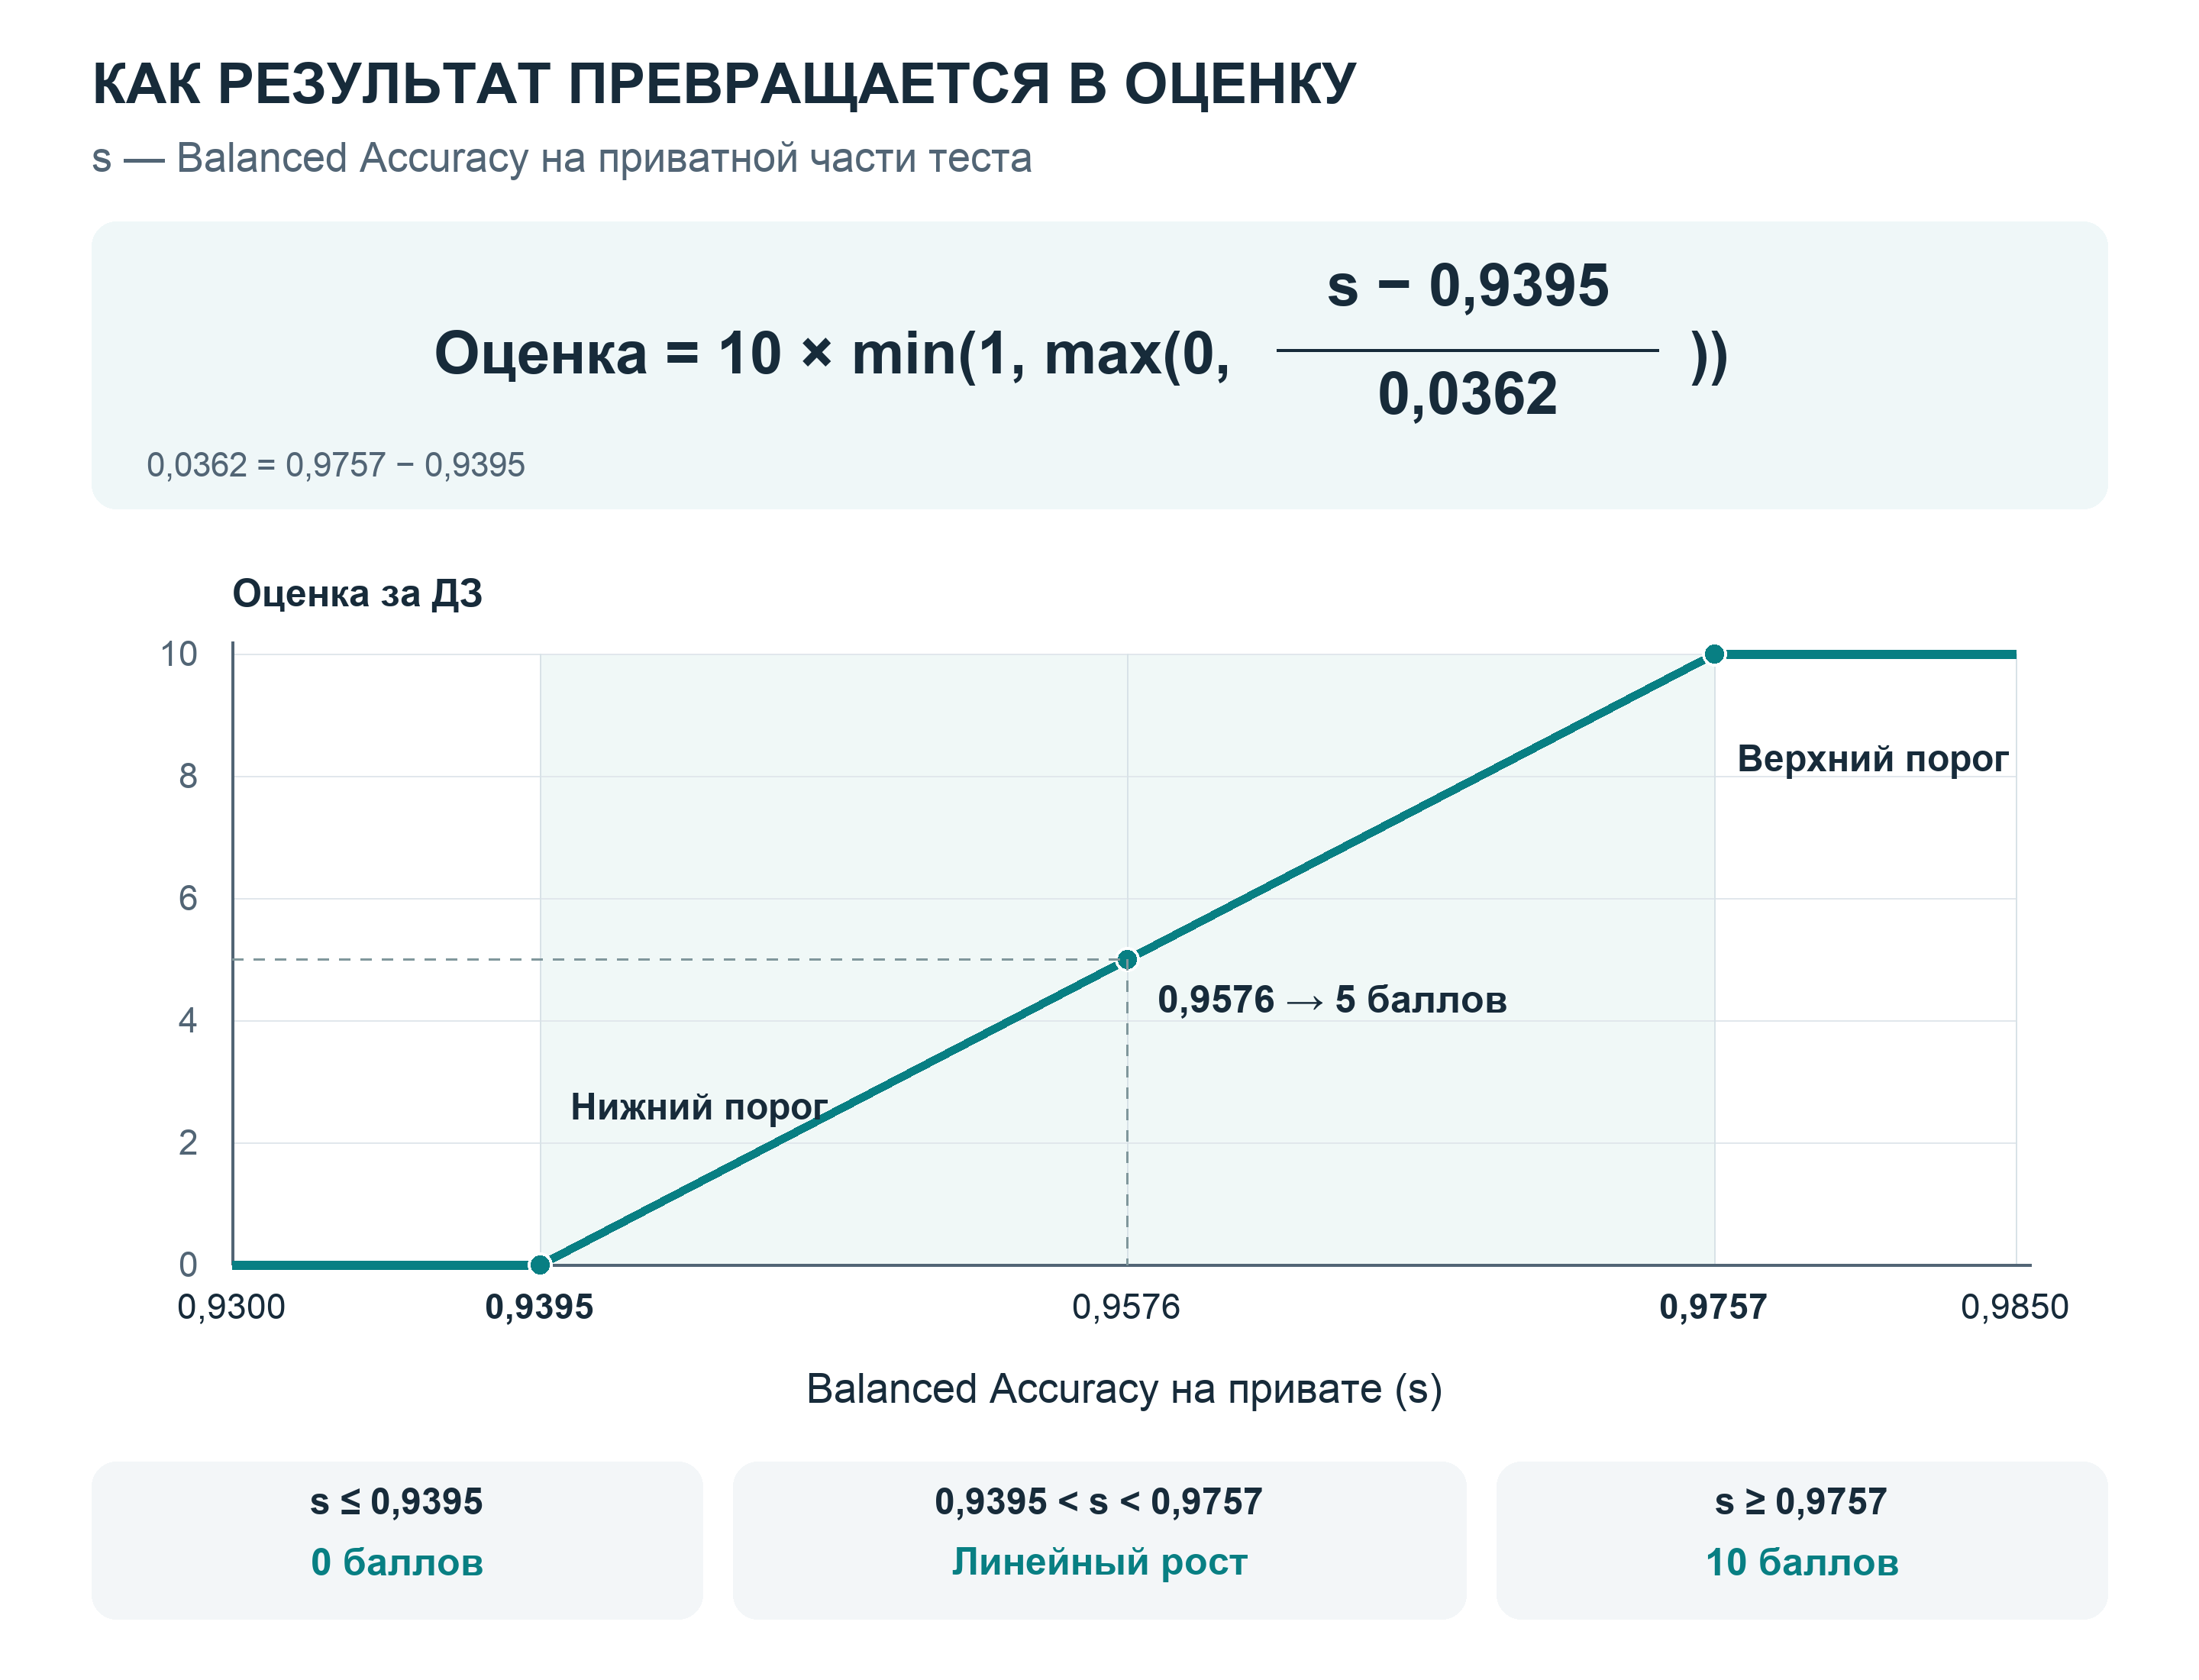

Например, при **s = 0,9576** оценка равна **5 баллам**. При **s = 0,9500** — примерно **2,90 балла**. Оценка ограничена диапазоном от 0 до 10; результат записывается с точностью до двух знаков после запятой.

Публичный результат нужен для обратной связи во время соревнования. Он не заменяет результат на private при выставлении оценки.

**Что нужно от вас для оценки:**

- В ноутбуке, который вы сдаёте в LMS, коротко поясните, за счёт чего ваш скор выше, чем у базового решения из этого ноутбука: что вы добавили или изменили (признаки, обработку изображения, модель и её настройки) и что из этого дало заметный прирост. Достаточно нескольких предложений в ячейке «Пояснение к решению» в конце ноутбука.

## 13. Карточка участника — заполните перед сдачей

Замените текст в квадратных скобках своими данными. Имя в лидерборде должно позволять проверяющему однозначно найти ваш результат.

| Поле | Ваши данные |
|---|---|
| Фамилия и имя | [Впишите фамилию и имя] |
| Учебная группа | БПИ247 |
| Точное имя / ник в лидерборде | [Скопируйте имя из лидерборда] |

**Перед сдачей проверьте:**

- На платформе есть хотя бы одна успешно проверенная посылка с результатом.
- ФИО, группа и имя в лидерборде заполнены; имя указано без ошибок.
- Пояснение к решению в ячейке ниже заполнено.
- В LMS загружается файл `HW4_Фамилия_Имя.ipynb` до дедлайна.

**Для проверяющего:** найдите участника по указанному имени, возьмите его итоговый Balanced Accuracy на private и примените формулу из раздела 12. Значение метрики, вписанное студентом, или скриншот public для оценки не используются.

### Пояснение к решению

Базовое решение видит только яркость, контраст и разность по горизонтали, поэтому плохо различает направления текстур (BA на val 0,7646). Изменения:

1. **Признаки направления и масштаба текстуры** (дали основной прирост). Вариограммы: нормированный средний квадрат разности с соседом на лагах 1, 2, 3, 5, 7 px вдоль четырёх направлений (→, ↓, ↘, ↙) на трёх масштабах окна. Структурный тензор (ориентация и когерентность градиента), энергия лапласиана гауссиана для пятен. Яркость картинки нормирована целиком, признаки поделены на локальную дисперсию, поэтому не зависят от яркости и контраста.
2. **Сдвинутые окна** для пикселей у границы: те же вариограммы, посчитанные в окнах, сдвинутых на 3 и 6 px. Хотя бы одно из них лежит в одной текстуре, это уменьшает ошибки на стыках.
3. **Двухэтапный лес (auto-context).** Этап 1: два леса по 25 деревьев, обученные на разных картинках, дают out-of-fold вероятности классов. Этап 2 (50 деревьев) получает исходные признаки плюс карты этих вероятностей, сглаженные на 4 масштабах и сдвинутые на 4/8 px в 8 направлениях, то есть видит, какие классы вокруг пикселя. Итого 100 деревьев, 20 000 обучающих пикселей (по 10 000 с каждой картинки).
4. **Постобработка:** гауссово сглаживание карт вероятностей перед argmax, ширина подбирается на `val.png`. Убирает одиночные ошибочные пиксели внутри областей.